https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import warnings
warnings.filterwarnings('ignore')
import nltk
nltk.download('stopwords')
nltk.download('punkt')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter
from wordcloud import WordCloud

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Embedding, LSTM, Bidirectional, Dense, Dropout,
    GlobalMaxPooling1D, Conv1D, MaxPooling1D, Input, Flatten
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, accuracy_score
)

print("TensorFlow version:", tf.__version__)
print(" All libraries imported successfully!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


TensorFlow version: 2.19.0
 All libraries imported successfully!


In [ ]:
df = pd.read_csv('IMDB Dataset.csv', nrows=5000)
print("Shape:", df.shape)
print("\nFirst 3 rows:")
print(df.head(3))
print("\nClass Distribution:")
print(df['sentiment'].value_counts())


Shape: (5000, 2)

First 3 rows:
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive

Class Distribution:
sentiment
negative    2532
positive    2468
Name: count, dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     5000 non-null   object
 1   sentiment  5000 non-null   object
dtypes: object(2)
memory usage: 78.3+ KB


In [ ]:
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

df['review_length'] = df['review'].apply(lambda x: len(x.split()))
df['char_length']   = df['review'].apply(len)

print("\n Review Length Stats:")
print(df.groupby('sentiment')['review_length'].describe().round(2))


 Review Length Stats:
            count    mean     std   min    25%    50%     75%     max
sentiment                                                            
negative   2532.0  232.30  166.25  14.0  128.0  174.0  285.25  1010.0
positive   2468.0  230.14  175.72  24.0  124.0  171.0  285.00  1737.0


# Exploratory Data Analysis

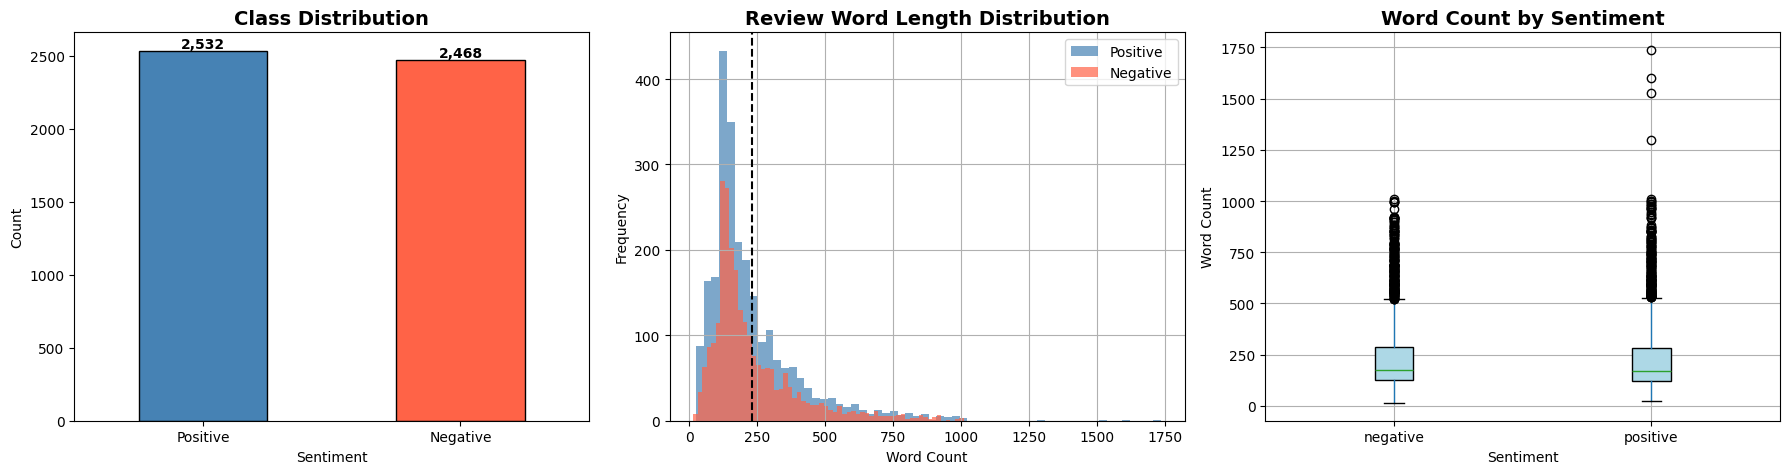


 Average review length: 231 words
 Max review length: 1737 words


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df['sentiment'].value_counts().plot(
    kind='bar', ax=axes[0], color=['steelblue','tomato'],
    edgecolor='black')
axes[0].set_title('Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['Positive', 'Negative'], rotation=0)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():,}',
                     (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontweight='bold')

df[df['sentiment']=='positive']['review_length'].hist(
    ax=axes[1], bins=60, color='steelblue', alpha=0.7, label='Positive')
df[df['sentiment']=='negative']['review_length'].hist(
    ax=axes[1], bins=60, color='tomato', alpha=0.7, label='Negative')
axes[1].set_title('Review Word Length Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].axvline(df['review_length'].mean(), color='black',
                linestyle='--', label=f"Mean={df['review_length'].mean():.0f}")

df.boxplot(column='review_length', by='sentiment', ax=axes[2],
           patch_artist=True,
           boxprops=dict(facecolor='lightblue'))
axes[2].set_title('Word Count by Sentiment', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Sentiment')
axes[2].set_ylabel('Word Count')
plt.suptitle('')
plt.tight_layout()
plt.savefig('eda_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\n Average review length: {df['review_length'].mean():.0f} words")
print(f" Max review length: {df['review_length'].max()} words")

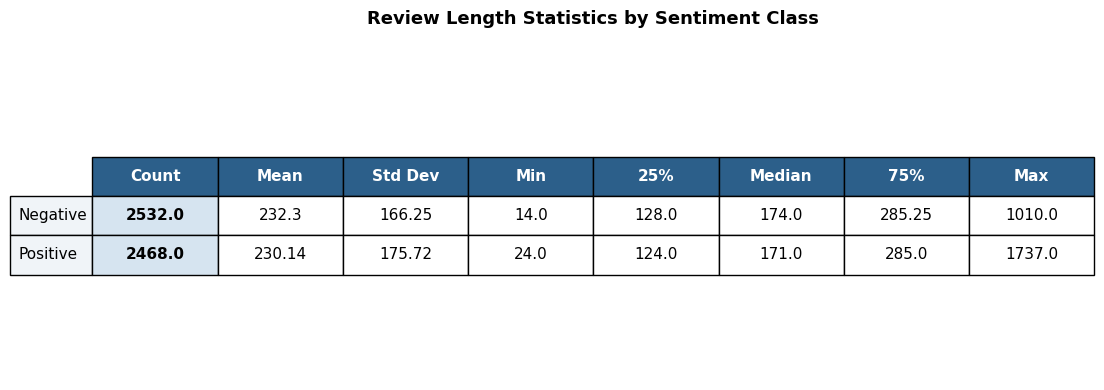

In [ ]:

fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('off')

stats = df.groupby('sentiment')['review_length'].describe().round(2)
stats.index = ['Negative', 'Positive']
stats.columns = ['Count', 'Mean', 'Std Dev', 'Min',
                 '25%', 'Median', '75%', 'Max']

table = ax.table(
    cellText=stats.values,
    colLabels=stats.columns,
    rowLabels=stats.index,
    cellLoc='center',
    loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.4, 2.2)

for j in range(len(stats.columns)):
    table[0, j].set_facecolor('#2c5f8a')
    table[0, j].set_text_props(color='white', fontweight='bold')

for i in range(1, 3):
    table[i, -1].set_facecolor('#f0f4f8')
    table[i, 0].set_facecolor('#d6e4f0')
    table[i, 0].set_text_props(fontweight='bold')

ax.set_title('Review Length Statistics by Sentiment Class',
             fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('eda_stats_table.png', dpi=150, bbox_inches='tight')
plt.show()

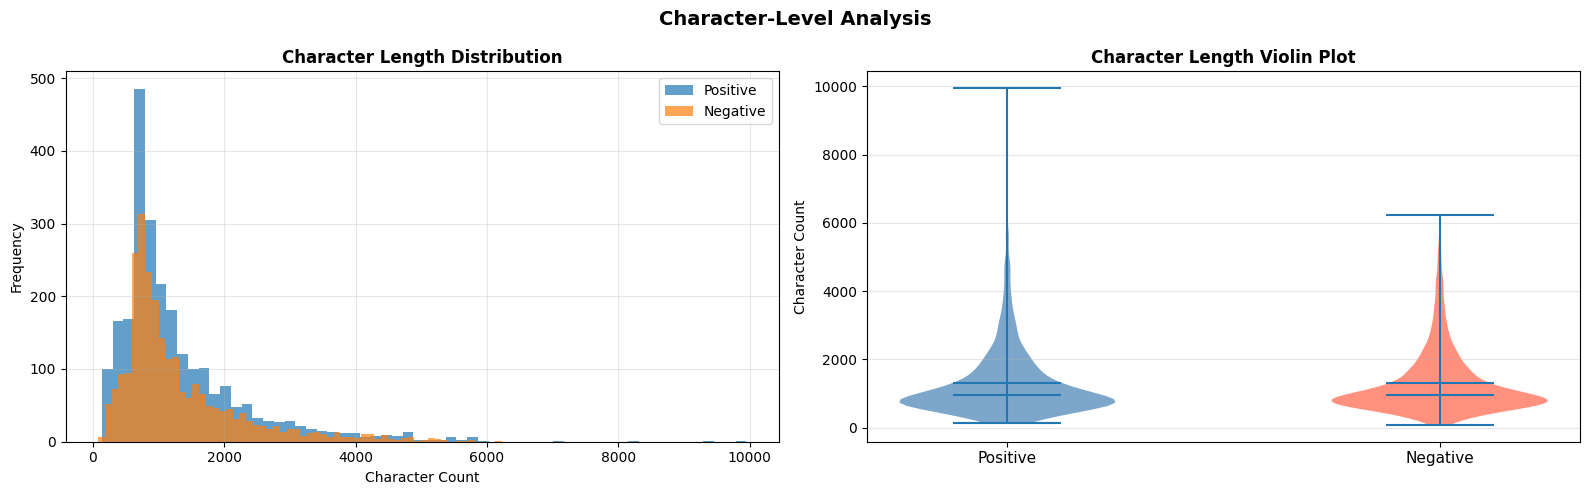

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Character-Level Analysis', fontsize=14, fontweight='bold')

df[df['sentiment']=='positive']['char_length'].hist(
    ax=axes[0], bins=60, alpha=0.7, label='Positive')
df[df['sentiment']=='negative']['char_length'].hist(
    ax=axes[0], bins=60, alpha=0.7, label='Negative')

axes[0].set_title('Character Length Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Character Count')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

data_to_plot = [
    df[df['sentiment']=='positive']['char_length'].values,
    df[df['sentiment']=='negative']['char_length'].values
]

parts = axes[1].violinplot(
    data_to_plot,
    positions=[1, 2],
    showmeans=True,
    showmedians=True
)

colors = ['steelblue', 'tomato']
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[i])
    pc.set_alpha(0.7)

axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(['Positive', 'Negative'], fontsize=11)
axes[1].set_title('Character Length Violin Plot', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Character Count')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Data Preprocessing

Cleaning text... (may take 30-60 seconds)

 BEFORE cleaning:
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" 

 AFTER cleaning:
wonderful little production filming technique unassuming old time bbc fashion gives comforting sometimes discomforting sense realism entire piece actors extremely well chosen michael sheen not got polari voices pat truly see seamless editing guided references williams diary entries not well worth wa


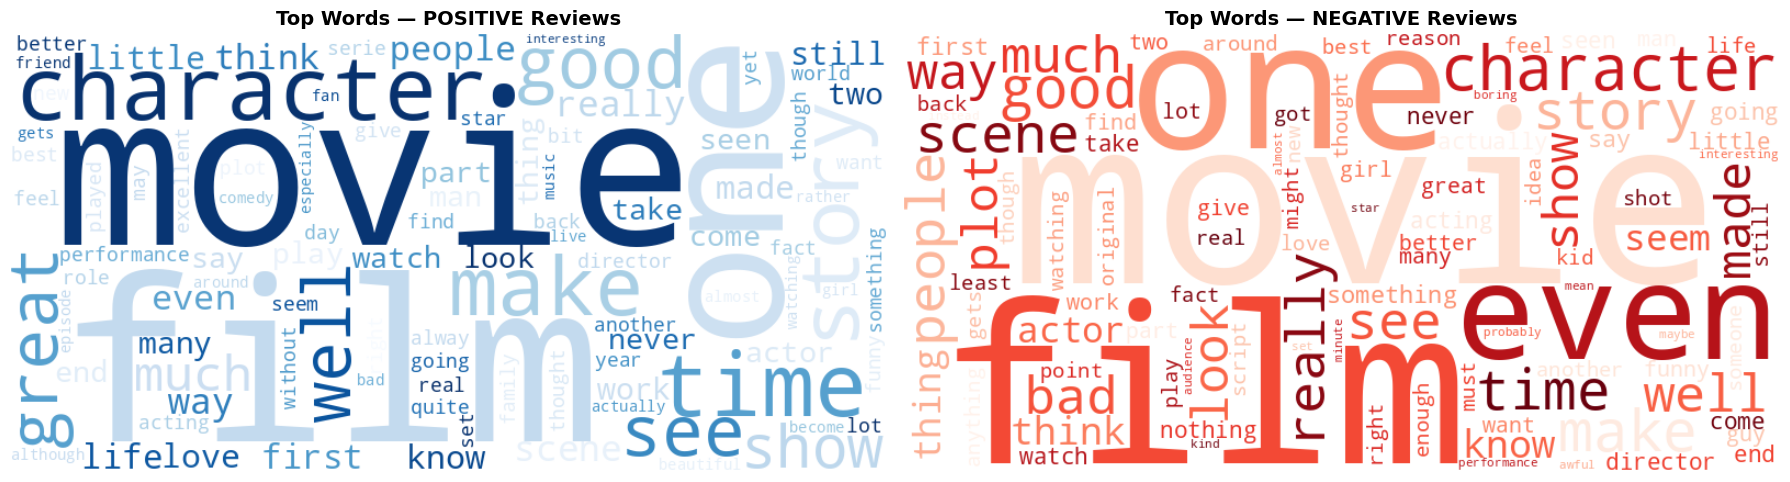

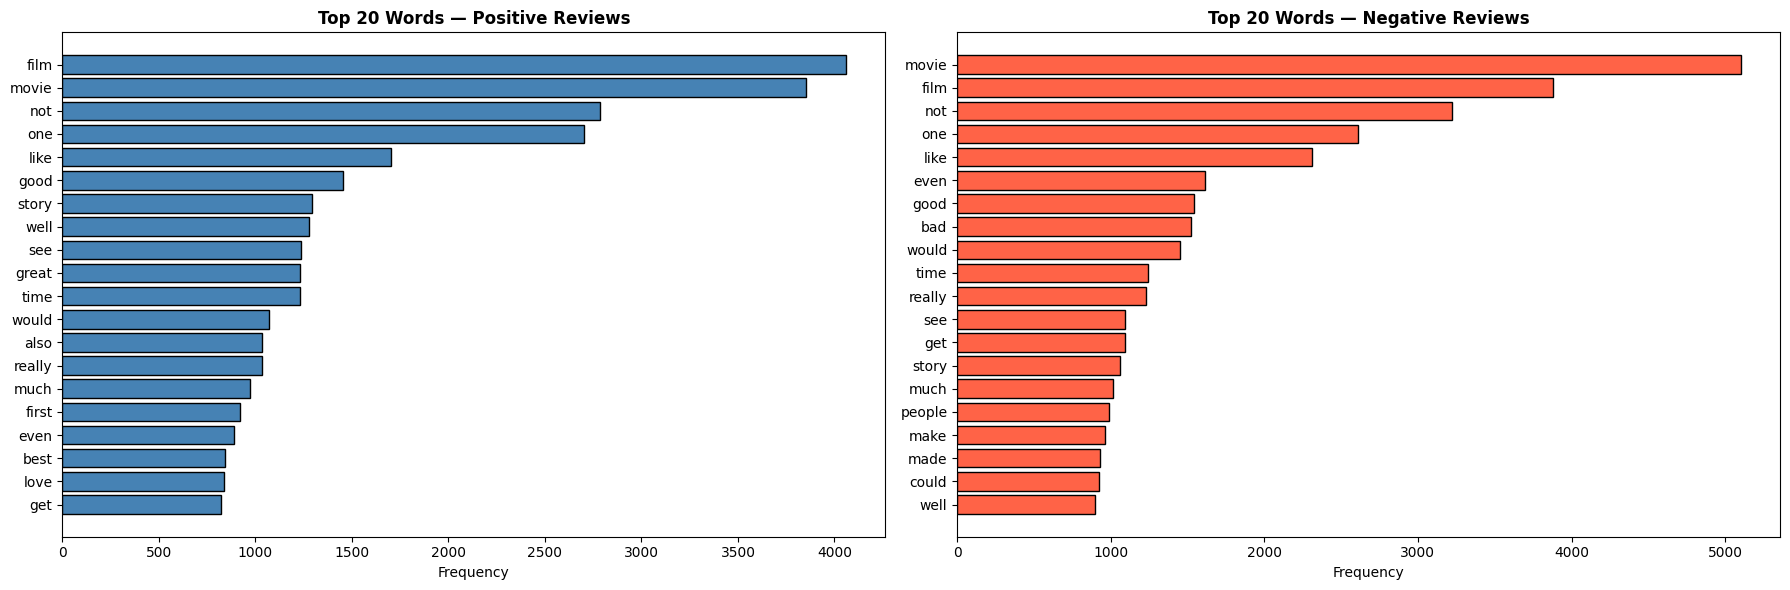

 Text cleaning complete!


In [ ]:
STOPWORDS = set(stopwords.words('english'))
NEGATION_WORDS = {'no','not','nor','neither','never','nothing',
                  'nobody','nowhere','hardly','barely','scarcely'}
STOPWORDS -= NEGATION_WORDS

def clean_text(text):
    """
    Full NLP preprocessing pipeline:
    1. Remove HTML tags
    2. Lowercase
    3. Remove special characters & numbers
    4. Remove stopwords (keeping negation)
    5. Remove extra whitespace
    """
    text = re.sub(r'<.*?>', ' ', text)
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = text.split()
    tokens = [w for w in tokens if w not in STOPWORDS and len(w) > 2]
    return ' '.join(tokens)

print("Cleaning text... (may take 30-60 seconds)")
df['cleaned_review'] = df['review'].apply(clean_text)

print("\n BEFORE cleaning:")
print(df['review'].iloc[1][:300])
print("\n AFTER cleaning:")
print(df['cleaned_review'].iloc[1][:300])

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

pos_text = ' '.join(df[df['label']==1]['cleaned_review'].tolist())
neg_text = ' '.join(df[df['label']==0]['cleaned_review'].tolist())

wc_pos = WordCloud(width=800, height=400, background_color='white',
                   colormap='Blues', max_words=100).generate(pos_text)
wc_neg = WordCloud(width=800, height=400, background_color='white',
                   colormap='Reds', max_words=100).generate(neg_text)

axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].set_title('Top Words — POSITIVE Reviews', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].set_title('Top Words — NEGATIVE Reviews', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.savefig('wordcloud_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

pos_words = Counter(' '.join(
    df[df['label']==1]['cleaned_review']).split()).most_common(20)
neg_words = Counter(' '.join(
    df[df['label']==0]['cleaned_review']).split()).most_common(20)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
words_p, counts_p = zip(*pos_words)
words_n, counts_n = zip(*neg_words)

axes[0].barh(words_p[::-1], counts_p[::-1], color='steelblue', edgecolor='black')
axes[0].set_title('Top 20 Words — Positive Reviews', fontweight='bold')
axes[0].set_xlabel('Frequency')

axes[1].barh(words_n[::-1], counts_n[::-1], color='tomato', edgecolor='black')
axes[1].set_title('Top 20 Words — Negative Reviews', fontweight='bold')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.savefig('top_words.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Text cleaning complete!")

# Data Splitting

In [ ]:
VOCAB_SIZE   = 10000
MAX_LEN      = 100
EMBED_DIM    = 64
BATCH_SIZE   = 128
EPOCHS       = 5

X = df['cleaned_review'].values
y = df['label'].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Train size:      {len(X_train):,} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation size: {len(X_val):,} ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test size:       {len(X_test):,} ({len(X_test)/len(X)*100:.1f}%)")

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

word_index = tokenizer.word_index
print(f"\n Vocabulary size: {len(word_index):,} unique words")
print(f" Using top {VOCAB_SIZE:,} words")

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq   = tokenizer.texts_to_sequences(X_val)
X_test_seq  = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_val_pad   = pad_sequences(X_val_seq,   maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad  = pad_sequences(X_test_seq,  maxlen=MAX_LEN, padding='post', truncating='post')

print(f"\n Padded shapes:")
print(f"   X_train: {X_train_pad.shape}")
print(f"   X_val:   {X_val_pad.shape}")
print(f"   X_test:  {X_test_pad.shape}")

review_lens = [len(s) for s in X_train_seq]
coverage = sum(1 for l in review_lens if l <= MAX_LEN) / len(review_lens) * 100
print(f"\n MAX_LEN={MAX_LEN} covers {coverage:.1f}% of training reviews")


Train size:      3,500 (70.0%)
Validation size: 750 (15.0%)
Test size:       750 (15.0%)

 Vocabulary size: 32,309 unique words
 Using top 10,000 words

 Padded shapes:
   X_train: (3500, 100)
   X_val:   (750, 100)
   X_test:  (750, 100)

 MAX_LEN=100 covers 58.3% of training reviews


# Model Architectures

In [ ]:
def build_cnn(vocab_size, embed_dim, max_len):
    model = Sequential([
        Embedding(vocab_size, embed_dim, input_length=max_len),
        Conv1D(64, kernel_size=5, activation='relu'),
        MaxPooling1D(pool_size=2),
        Conv1D(32, kernel_size=3, activation='relu'),
        GlobalMaxPooling1D(),
        Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.4),
        Dense(1, activation='sigmoid')
    ])
    return model

cnn_model = build_cnn(VOCAB_SIZE, EMBED_DIM, MAX_LEN)
cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
cnn_model.summary()

callbacks = [
    EarlyStopping(monitor='val_loss', patience=2,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=1, verbose=1)
]

print("\n Training CNN model...")
cnn_history = cnn_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

cnn_loss, cnn_acc = cnn_model.evaluate(X_test_pad, y_test, verbose=0)
print(f"\n CNN Test Accuracy: {cnn_acc*100:.2f}%")
print(f" CNN Test Loss:     {cnn_loss:.4f}")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


 Training CNN model...
Epoch 1/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 14s 127ms/step - accuracy: 0.5034 - loss: 0.7219 - val_accuracy: 0.5067 - val_loss: 0.7174 - learning_rate: 0.0010
Epoch 2/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6537 - loss: 0.7028 - val_accuracy: 0.6120 - val_loss: 0.7071 - learning_rate: 0.0010
Epoch 3/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7317 - loss: 0.6563 - val_accuracy: 0.6600 - val_loss: 0.6460 - learning_rate: 0.0010
Epoch 4/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8589 - loss: 0.4742 - val_accuracy: 0.7947 - val_loss: 0.4573 - learning_rate: 0.0010
Epoch 5/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9294 - loss: 0.2364 - val_accuracy: 0.8187 - val_loss: 0.4250 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.

 CNN Test Accuracy: 83.33%
 CNN Test Loss:     0.4171


In [ ]:
def build_lstm(vocab_size, embed_dim, max_len):
    model = Sequential([
        Embedding(vocab_size, embed_dim, input_length=max_len),
        LSTM(64, dropout=0.2, recurrent_dropout=0.2,
             return_sequences=True),
        LSTM(32, dropout=0.2, recurrent_dropout=0.2),
        Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    return model

lstm_model = build_lstm(VOCAB_SIZE, EMBED_DIM, MAX_LEN)
lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
lstm_model.summary()

lstm_callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=3,
                  restore_best_weights=True, verbose=1, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=1, verbose=1, min_lr=1e-6)
]

print("\n Training LSTM model...")
lstm_history = lstm_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=lstm_callbacks,
    verbose=1
)

lstm_loss, lstm_acc = lstm_model.evaluate(X_test_pad, y_test, verbose=0)
print(f"\n LSTM Test Accuracy: {lstm_acc*100:.2f}%")
print(f" LSTM Test Loss:     {lstm_loss:.4f}")


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


 Training LSTM model...
Epoch 1/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.4983 - loss: 0.7218 - val_accuracy: 0.4920 - val_loss: 0.7181 - learning_rate: 0.0010
Epoch 2/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 27s 938ms/step - accuracy: 0.5226 - loss: 0.7144 - val_accuracy: 0.4880 - val_loss: 0.7123 - learning_rate: 0.0010
Epoch 3/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 21s 730ms/step - accuracy: 0.6257 - loss: 0.6820 - val_accuracy: 0.7680 - val_loss: 0.5548 - learning_rate: 0.0010
Epoch 4/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - accuracy: 0.8037 - loss: 0.5281
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
28/28 ━━━━━━━━━━━━━━━━━━━━ 21s 750ms/step - accuracy: 0.7969 - loss: 0.5292 - val_accuracy: 0.7320 - val_loss: 0.5673 - learning_rate: 0.0010
Epoch 5/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 21s 746ms/step - accuracy: 0.8711 - loss: 0.3972 - val_accuracy: 0.7893 - val_loss: 0.5286 - learning_rate: 5.0000e-04
Restoring model weights from the end of the best epoch: 5.

 LS

In [ ]:
def build_bilstm(vocab_size, embed_dim, max_len):
    model = Sequential([
        Embedding(vocab_size, embed_dim, input_length=max_len, mask_zero=True),
        Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.2,
                           return_sequences=True)),
        Bidirectional(LSTM(32, dropout=0.3, recurrent_dropout=0.2)),
        Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.5),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    return model

bilstm_model = build_bilstm(VOCAB_SIZE, EMBED_DIM, MAX_LEN)
bilstm_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
bilstm_model.summary()

best_callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=3,
                  restore_best_weights=True, verbose=1, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                      patience=1, verbose=1, min_lr=1e-6)
]

print("\n Training Bidirectional LSTM model...")
bilstm_history = bilstm_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=best_callbacks,
    verbose=1
)

bilstm_loss, bilstm_acc = bilstm_model.evaluate(X_test_pad, y_test, verbose=0)
print(f"\n BiLSTM Test Accuracy: {bilstm_acc*100:.2f}%")
print(f" BiLSTM Test Loss:     {bilstm_loss:.4f}")


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


 Training Bidirectional LSTM model...
Epoch 1/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - accuracy: 0.5123 - loss: 0.7520 - val_accuracy: 0.5187 - val_loss: 0.7462 - learning_rate: 5.0000e-04
Epoch 2/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.5260 - loss: 0.7410 - val_accuracy: 0.5400 - val_loss: 0.7354 - learning_rate: 5.0000e-04
Epoch 3/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.6283 - loss: 0.7153 - val_accuracy: 0.7693 - val_loss: 0.6302 - learning_rate: 5.0000e-04
Epoch 4/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.8269 - loss: 0.4951 - val_accuracy: 0.8147 - val_loss: 0.4670 - learning_rate: 5.0000e-04
Epoch 5/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9005 - loss: 0.3393
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
28/28 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.9166 - loss: 0.3103 - val_accuracy: 0.8093 - val_loss: 0.4971 - learning_rate: 5.0000e-04
Restoring model weights from the end of the best

# Training Configuration

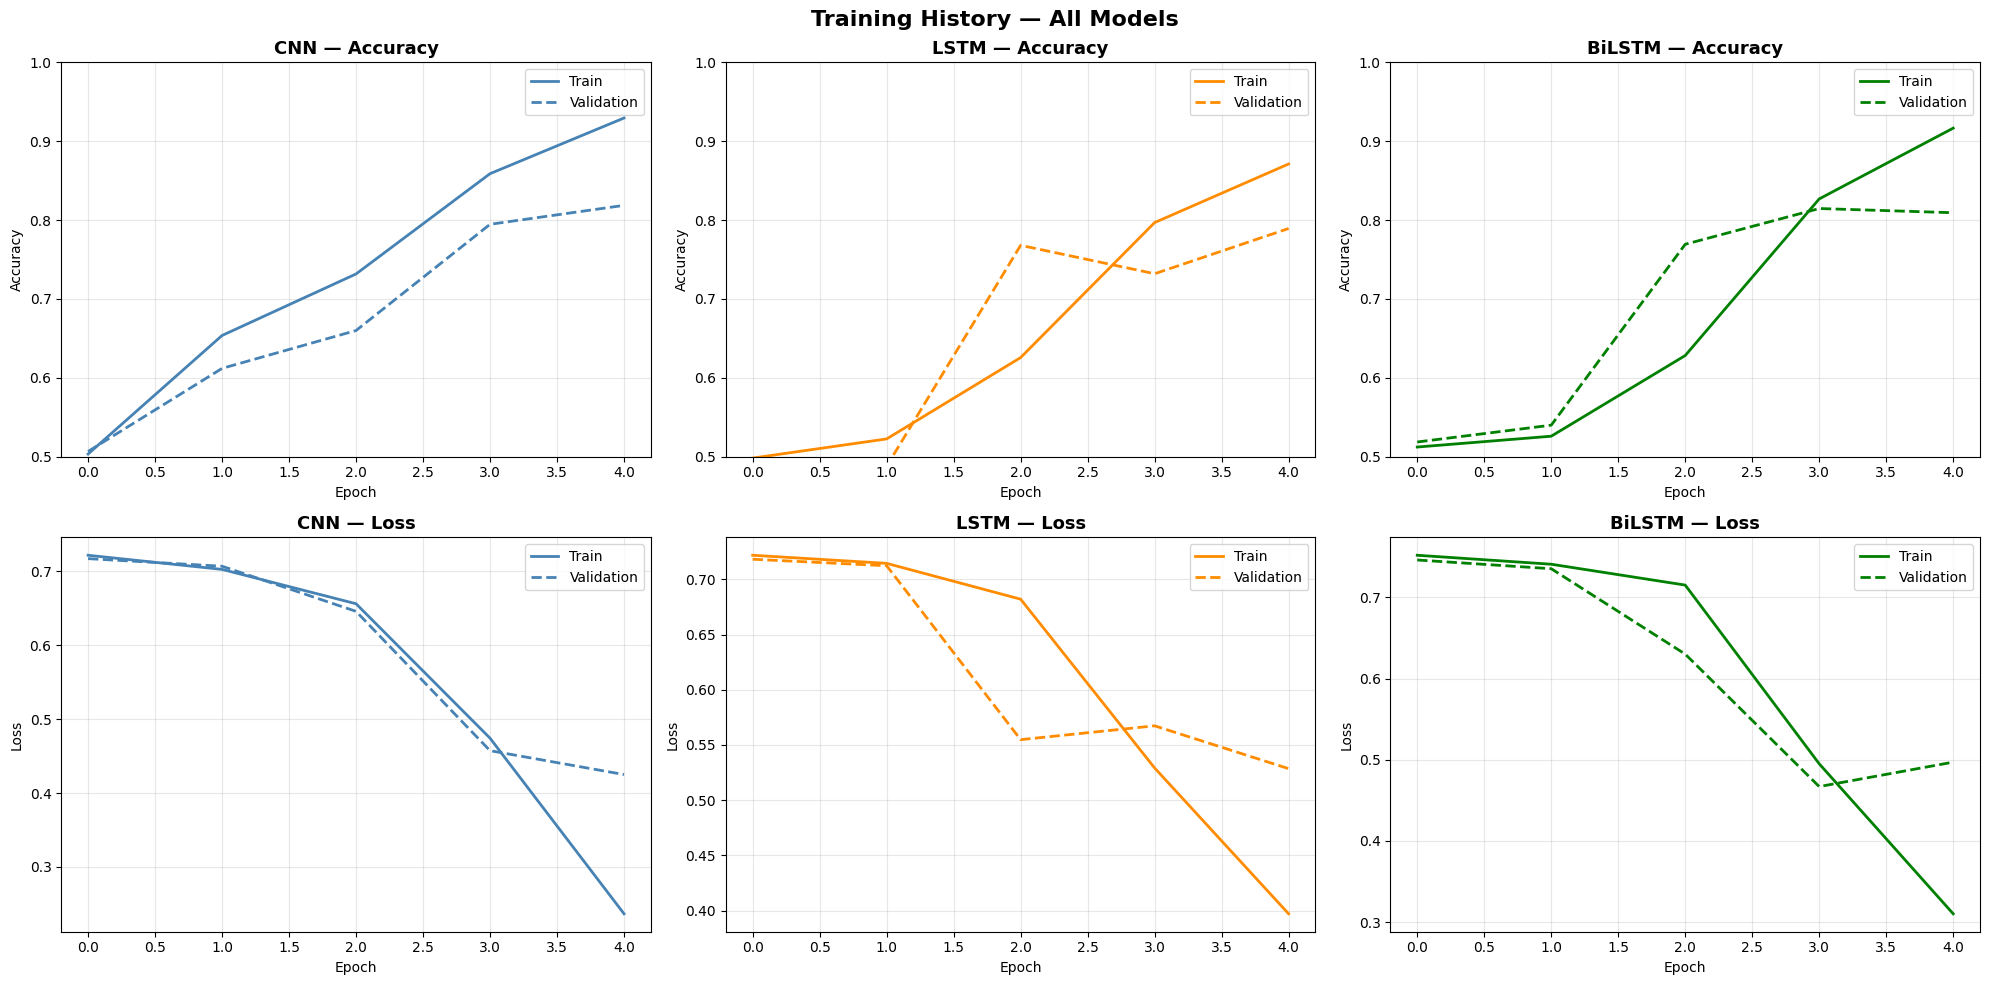

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

histories = {
    'CNN':   cnn_history,
    'LSTM':  lstm_history,
    'BiLSTM': bilstm_history
}
colors = ['steelblue', 'darkorange', 'green']
\
for idx, (name, hist) in enumerate(histories.items()):

    axes[0, idx].plot(hist.history['accuracy'],
                      label='Train', color=colors[idx], linewidth=2)
    axes[0, idx].plot(hist.history['val_accuracy'],
                      label='Validation', color=colors[idx],
                      linestyle='--', linewidth=2)
    axes[0, idx].set_title(f'{name} — Accuracy', fontsize=13, fontweight='bold')
    axes[0, idx].set_xlabel('Epoch')
    axes[0, idx].set_ylabel('Accuracy')
    axes[0, idx].legend()
    axes[0, idx].grid(True, alpha=0.3)
    axes[0, idx].set_ylim([0.5, 1.0])

    axes[1, idx].plot(hist.history['loss'],
                      label='Train', color=colors[idx], linewidth=2)
    axes[1, idx].plot(hist.history['val_loss'],
                      label='Validation', color=colors[idx],
                      linestyle='--', linewidth=2)
    axes[1, idx].set_title(f'{name} — Loss', fontsize=13, fontweight='bold')
    axes[1, idx].set_xlabel('Epoch')
    axes[1, idx].set_ylabel('Loss')
    axes[1, idx].legend()
    axes[1, idx].grid(True, alpha=0.3)

plt.suptitle('Training History — All Models', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()

# Results & Evaluation


  Model: CNN
  Accuracy:  83.33%
  ROC-AUC:   0.9056

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.86      0.84       380
    Positive       0.85      0.81      0.83       370

    accuracy                           0.83       750
   macro avg       0.83      0.83      0.83       750
weighted avg       0.83      0.83      0.83       750


  Model: LSTM
  Accuracy:  79.20%
  ROC-AUC:   0.8635

Classification Report:
              precision    recall  f1-score   support

    Negative       0.80      0.78      0.79       380
    Positive       0.78      0.81      0.79       370

    accuracy                           0.79       750
   macro avg       0.79      0.79      0.79       750
weighted avg       0.79      0.79      0.79       750


  Model: BiLSTM
  Accuracy:  83.33%
  ROC-AUC:   0.9126

Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.81      0.83       380

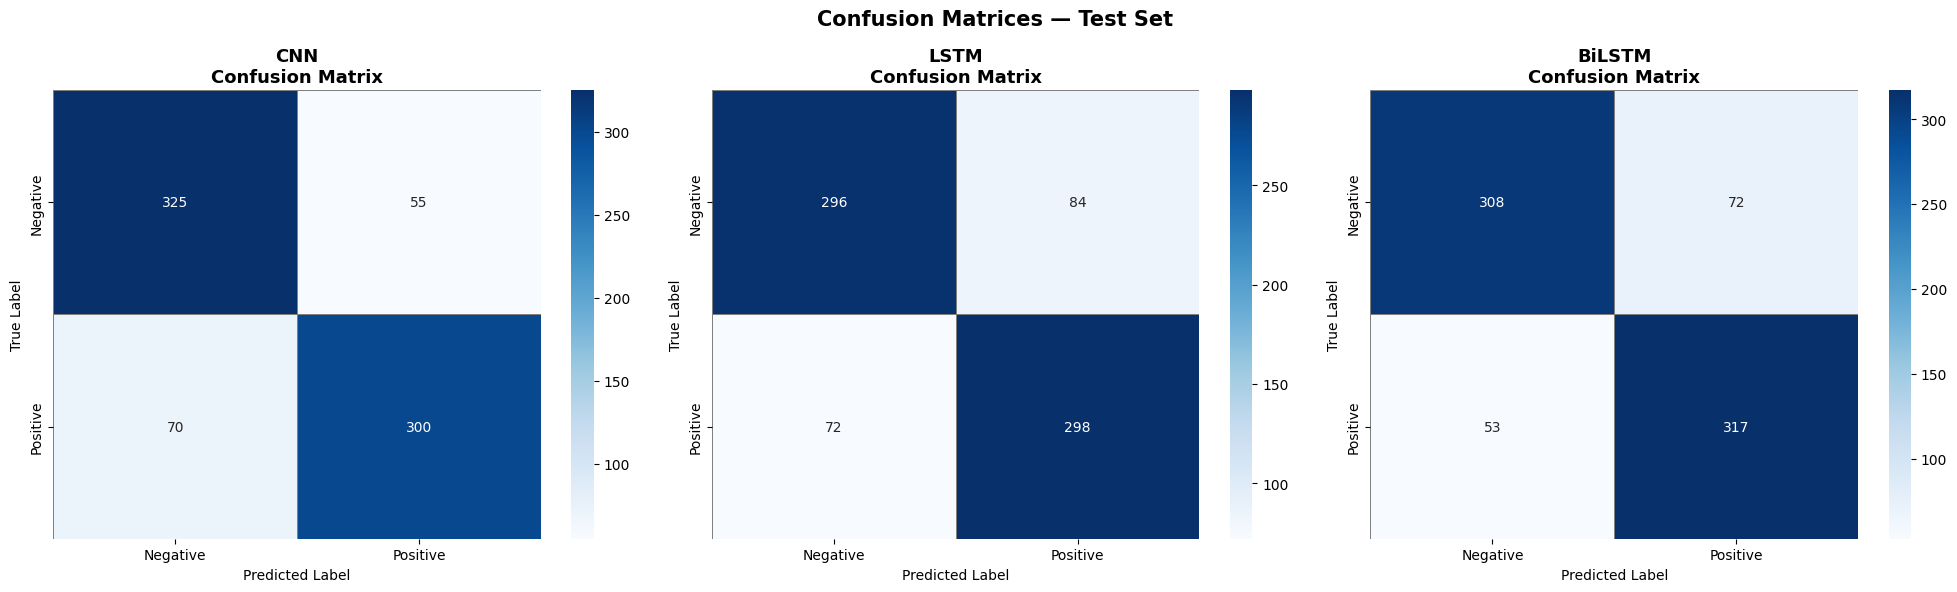

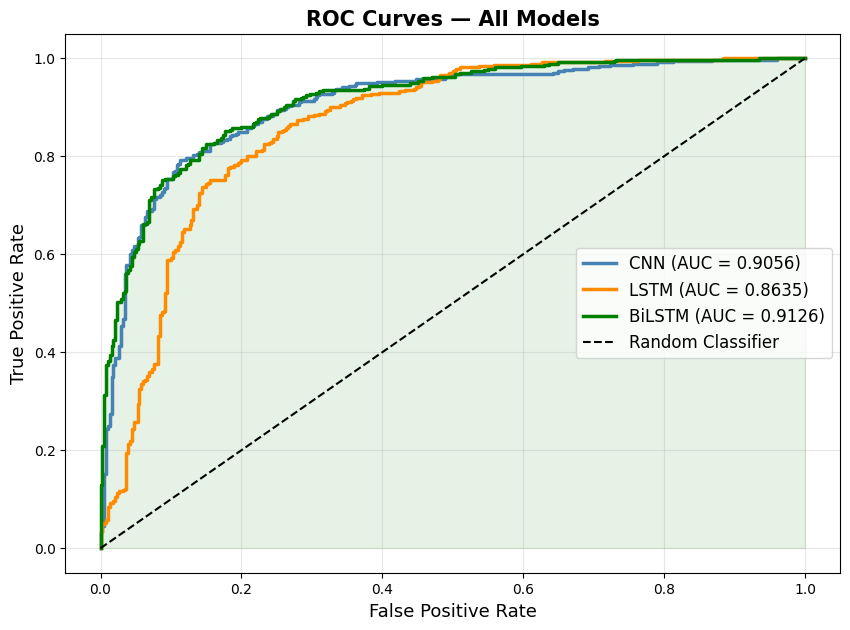

In [ ]:
def evaluate_model(model, name, X_test, y_test):
    y_pred_prob = model.predict(X_test, verbose=0).flatten()
    y_pred      = (y_pred_prob >= 0.5).astype(int)

    acc    = accuracy_score(y_test, y_pred)
    auc    = roc_auc_score(y_test, y_pred_prob)
    report = classification_report(y_test, y_pred,
                                   target_names=['Negative','Positive'])
    cm     = confusion_matrix(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_pred_prob)

    print(f"\n{'='*50}")
    print(f"  Model: {name}")
    print(f"{'='*50}")
    print(f"  Accuracy:  {acc*100:.2f}%")
    print(f"  ROC-AUC:   {auc:.4f}")
    print(f"\nClassification Report:\n{report}")

    return y_pred, y_pred_prob, cm, fpr, tpr, auc

results = {}
for name, model in [('CNN', cnn_model),
                    ('LSTM', lstm_model),
                    ('BiLSTM', bilstm_model)]:
    y_pred, y_prob, cm, fpr, tpr, auc = evaluate_model(
        model, name, X_test_pad, y_test)
    results[name] = {
        'y_pred': y_pred, 'y_prob': y_prob,
        'cm': cm, 'fpr': fpr, 'tpr': tpr, 'auc': auc
    }

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for idx, (name, res) in enumerate(results.items()):
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negative','Positive'],
                yticklabels=['Negative','Positive'],
                ax=axes[idx], linewidths=0.5, linecolor='gray')
    axes[idx].set_title(f'{name}\nConfusion Matrix', fontweight='bold', fontsize=13)
    axes[idx].set_ylabel('True Label')
    axes[idx].set_xlabel('Predicted Label')

plt.suptitle('Confusion Matrices — Test Set', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 7))
colors = {'CNN':'steelblue', 'LSTM':'darkorange', 'BiLSTM':'green'}
for name, res in results.items():
    plt.plot(res['fpr'], res['tpr'],
             label=f"{name} (AUC = {res['auc']:.4f})",
             color=colors[name], linewidth=2.5)
plt.plot([0,1],[0,1], 'k--', linewidth=1.5, label='Random Classifier')
plt.fill_between(results['BiLSTM']['fpr'],
                 results['BiLSTM']['tpr'], alpha=0.1, color='green')
plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.title('ROC Curves — All Models', fontsize=15, fontweight='bold')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
comparison_data = {
    'Model':       ['CNN (Baseline)', 'LSTM', 'BiLSTM (Best)'],
    'Architecture': ['Conv1D → MaxPool → Dense',
                     'LSTM × 2 → Dense',
                     'BiLSTM × 2 → Dense'],
    'Parameters':  [
        f"{cnn_model.count_params():,}",
        f"{lstm_model.count_params():,}",
        f"{bilstm_model.count_params():,}"
    ],
    'Test Accuracy': [
        f"{cnn_acc*100:.2f}%",
        f"{lstm_acc*100:.2f}%",
        f"{bilstm_acc*100:.2f}%"
    ],
    'ROC-AUC': [
        f"{results['CNN']['auc']:.4f}",
        f"{results['LSTM']['auc']:.4f}",
        f"{results['BiLSTM']['auc']:.4f}"
    ]
}

df_compare = pd.DataFrame(comparison_data)
print("\n" + "="*70)
print("           MODEL COMPARISON SUMMARY TABLE")
print(df_compare.to_string(index=False))



           MODEL COMPARISON SUMMARY TABLE
         Model             Architecture Parameters Test Accuracy ROC-AUC
CNN (Baseline) Conv1D → MaxPool → Dense    667,809        83.33%  0.9056
          LSTM         LSTM × 2 → Dense    686,529        79.20%  0.8635
 BiLSTM (Best)       BiLSTM × 2 → Dense    753,537        83.33%  0.9126


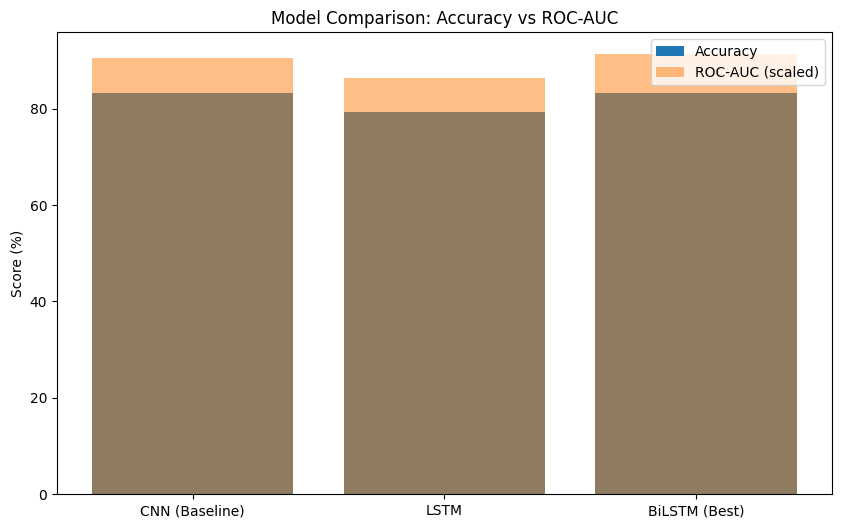

In [ ]:
import matplotlib.pyplot as plt

df_compare['Test Accuracy'] = df_compare['Test Accuracy'].str.replace('%','').astype(float)
df_compare['ROC-AUC'] = df_compare['ROC-AUC'].astype(float)

plt.figure(figsize=(10,6))

x = range(len(df_compare))

plt.bar(x, df_compare['Test Accuracy'], label='Accuracy')
plt.bar(x, df_compare['ROC-AUC']*100, bottom=0, alpha=0.5, label='ROC-AUC (scaled)')

plt.xticks(x, df_compare['Model'])
plt.ylabel('Score (%)')
plt.title('Model Comparison: Accuracy vs ROC-AUC')
plt.legend()

plt.show()

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score
import pandas as pd

all_results = []

for name, model in [('CNN', cnn_model), ('LSTM', lstm_model), ('BiLSTM', bilstm_model)]:

    y_prob = model.predict(X_test_pad, verbose=0)

    if y_prob.shape[1] == 1:
        y_pred = (y_prob >= 0.5).astype(int).flatten()
        y_prob_flat = y_prob.flatten()
    else:
        y_pred = y_prob.argmax(axis=1)
        y_prob_flat = y_prob

    report = classification_report(y_test, y_pred, output_dict=True)

    result = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred) * 100,
        'Precision (Macro)': report['macro avg']['precision'] * 100,
        'Recall (Macro)': report['macro avg']['recall'] * 100,
        'F1 (Macro)': report['macro avg']['f1-score'] * 100,
        'Precision (Weighted)': report['weighted avg']['precision'] * 100,
        'Recall (Weighted)': report['weighted avg']['recall'] * 100,
        'F1 (Weighted)': report['weighted avg']['f1-score'] * 100,
    }

    try:
        if y_prob.shape[1] == 1:
            result['ROC-AUC'] = roc_auc_score(y_test, y_prob_flat) * 100
        else:
            result['ROC-AUC'] = roc_auc_score(y_test, y_prob, multi_class='ovr') * 100
    except:
        result['ROC-AUC'] = None

    for cls in report:
        if cls not in ['accuracy', 'macro avg', 'weighted avg']:
            result[f'F1_Class_{cls}'] = report[cls]['f1-score'] * 100

    all_results.append(result)

df_all_metrics = pd.DataFrame(all_results)

print("\n FULL METRICS FOR ALL MODELS:\n")
print(df_all_metrics.to_string(index=False))


 FULL METRICS FOR ALL MODELS:

 Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 (Macro)  Precision (Weighted)  Recall (Weighted)  F1 (Weighted)   ROC-AUC  F1_Class_0  F1_Class_1
   CNN 83.333333          83.392762       83.303698   83.314794             83.377905          83.333333      83.322210 90.559744   83.870968   82.758621
  LSTM 79.200000          79.222627       79.217639   79.199852             79.238789          79.200000      79.199113 86.348506   79.144385   79.255319
BiLSTM 83.333333          83.404781       83.364154   83.330933             83.430298          83.333333      83.328266 91.258890   83.130904   83.530962


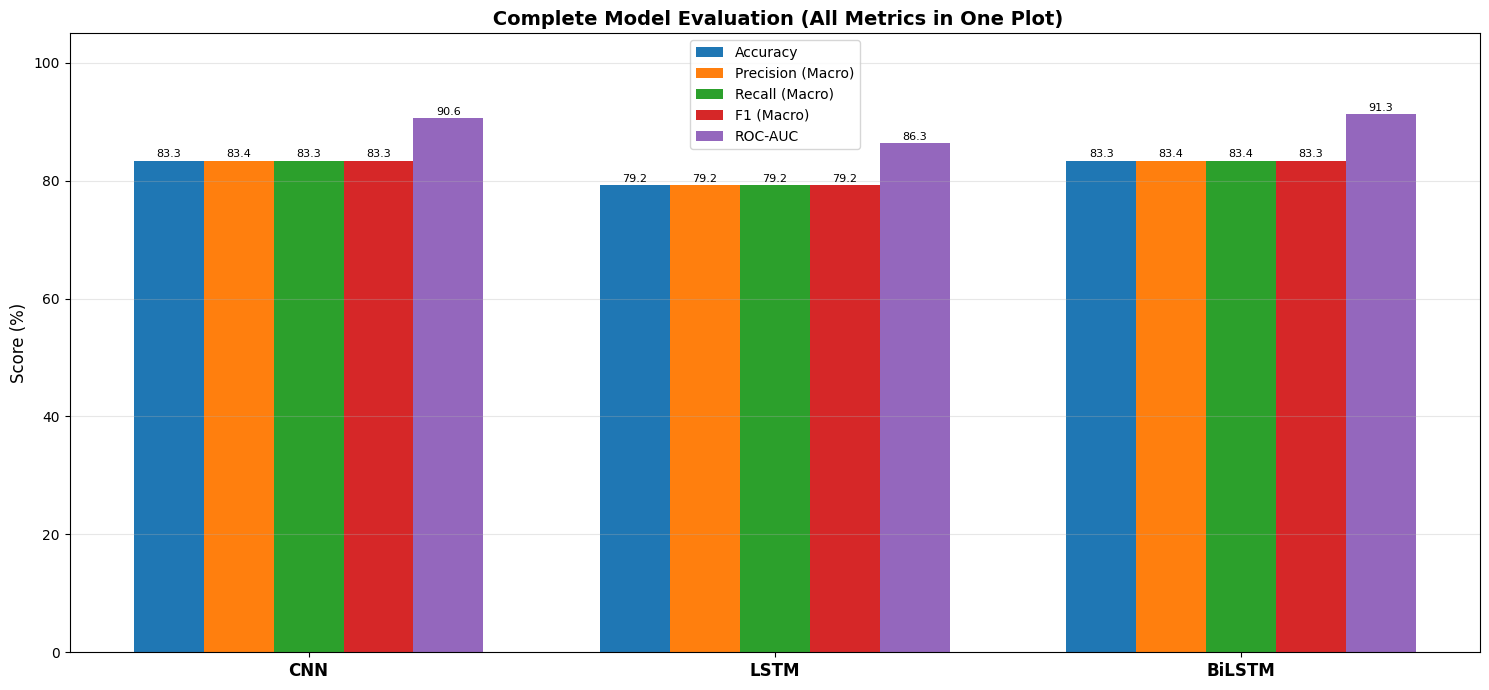

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plot_metrics = [
    'Accuracy',
    'Precision (Macro)',
    'Recall (Macro)',
    'F1 (Macro)',
    'ROC-AUC'
]

df_plot = df_all_metrics.copy()
df_plot = df_plot.fillna(0)

x = np.arange(len(df_plot))
width = 0.15

plt.figure(figsize=(15,7))

for i, metric in enumerate(plot_metrics):
    bars = plt.bar(x + i*width, df_plot[metric], width, label=metric)

    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{bar.get_height():.1f}',
            ha='center',
            va='bottom',
            fontsize=8
        )

plt.xticks(x + width*2, df_plot['Model'], fontsize=12, fontweight='bold')
plt.ylabel('Score (%)', fontsize=12)
plt.title(' Complete Model Evaluation (All Metrics in One Plot)', fontsize=14, fontweight='bold')
plt.ylim(0, 105)

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('all_metrics_single_plot.png', dpi=150, bbox_inches='tight')
plt.show()

# Error Analysis

Total misclassified by BiLSTM: 125 / 750
Error rate: 16.67%

  MISCLASSIFIED EXAMPLES — Critical Analysis

Example 1:
  True Label:      NEGATIVE
  Predicted:       POSITIVE  ← WRONG
  Confidence:      0.8716
  Review snippet:  comic strip featured actors young one student based sitcom comic strip features included parodies westerns famous professionals lot funnier said alexe...
------------------------------------------------------------

Example 2:
  True Label:      NEGATIVE
  Predicted:       POSITIVE  ← WRONG
  Confidence:      0.6488
  Review snippet:  get big premises episode miranda remarkable anything ugly would make insane someone made remark maybe frequency light waves something rather ugliness ...
------------------------------------------------------------

Example 3:
  True Label:      NEGATIVE
  Predicted:       POSITIVE  ← WRONG
  Confidence:      0.7902
  Review snippet:  synopsis movie led believe would story unconventional woman challenging conventions society lives 

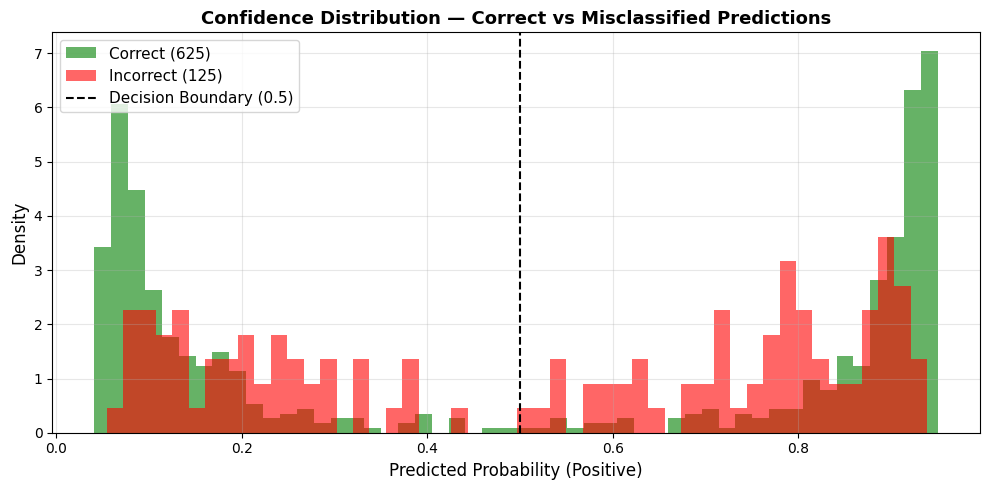

In [ ]:
y_bilstm_prob = bilstm_model.predict(X_test_pad, verbose=0).flatten()
y_bilstm_pred = (y_bilstm_prob >= 0.5).astype(int)

errors_idx = np.where(y_bilstm_pred != y_test)[0]
print(f"Total misclassified by BiLSTM: {len(errors_idx)} / {len(y_test)}")
print(f"Error rate: {len(errors_idx)/len(y_test)*100:.2f}%\n")

print("="*70)
print("  MISCLASSIFIED EXAMPLES — Critical Analysis")
print("="*70)
for i, idx in enumerate(errors_idx[:5]):
    true_label = "POSITIVE" if y_test[idx] == 1 else "NEGATIVE"
    pred_label = "POSITIVE" if y_bilstm_pred[idx] == 1 else "NEGATIVE"
    conf       = y_bilstm_prob[idx]
    print(f"\nExample {i+1}:")
    print(f"  True Label:      {true_label}")
    print(f"  Predicted:       {pred_label}  ← WRONG")
    print(f"  Confidence:      {conf:.4f}")
    print(f"  Review snippet:  {X_test[idx][:150]}...")
    print("-"*60)

correct_conf = y_bilstm_prob[y_bilstm_pred == y_test]
wrong_conf   = y_bilstm_prob[y_bilstm_pred != y_test]

plt.figure(figsize=(10, 5))
plt.hist(correct_conf, bins=50, alpha=0.6,
         color='green', label=f'Correct ({len(correct_conf):,})', density=True)
plt.hist(wrong_conf, bins=50, alpha=0.6,
         color='red', label=f'Incorrect ({len(wrong_conf):,})', density=True)
plt.axvline(0.5, color='black', linestyle='--', label='Decision Boundary (0.5)')
plt.xlabel('Predicted Probability (Positive)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.title('Confidence Distribution — Correct vs Misclassified Predictions',
          fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Model Saving

In [ ]:
import pickle, json

bilstm_model.save('bilstm_sentiment_model.h5')
print(" BiLSTM model saved: bilstm_sentiment_model.h5")

with open('tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)
print(" Tokeniser saved: tokenizer.pkl")

config = {
    'vocab_size':   VOCAB_SIZE,
    'max_len':      MAX_LEN,
    'embed_dim':    EMBED_DIM,
    'batch_size':   BATCH_SIZE,
    'epochs_run':   len(bilstm_history.history['accuracy']),
    'test_accuracy': f"{bilstm_acc*100:.2f}%",
    'auc_score':    f"{results['BiLSTM']['auc']:.4f}"
}
with open('model_config.json', 'w') as f:
    json.dump(config, f, indent=2)
print(" Config saved: model_config.json")
print("\n Final Best Model Performance:")
print(f"    Test Accuracy: {bilstm_acc*100:.2f}%")
print(f"    ROC-AUC Score: {results['BiLSTM']['auc']:.4f}")
print(f"    Model: Bidirectional LSTM")
print(f"    Dataset: 50,000 IMDB Reviews")

 BiLSTM model saved: bilstm_sentiment_model.h5
 Tokeniser saved: tokenizer.pkl
 Config saved: model_config.json

 Final Best Model Performance:
    Test Accuracy: 83.33%
    ROC-AUC Score: 0.9126
    Model: Bidirectional LSTM
    Dataset: 50,000 IMDB Reviews


In [ ]:
def predict_sentiment(review_text, model, tokenizer, max_len=200):
    cleaned     = clean_text(review_text)
    seq         = tokenizer.texts_to_sequences([cleaned])
    padded      = pad_sequences(seq, maxlen=max_len,
                                padding='post', truncating='post')
    probability = model.predict(padded, verbose=0)[0][0]
    sentiment   = "POSITIVE " if probability >= 0.5 else "NEGATIVE "
    confidence  = probability if probability >= 0.5 else 1 - probability
    return sentiment, float(probability), float(confidence)

test_reviews = [
    "This film is absolutely brilliant! Best movie I have seen in years. "
    "The acting was superb and the story kept me gripped throughout.",

    "Terrible waste of time. The plot made no sense and the acting was "
    "wooden and unconvincing. I walked out halfway through.",

    "Not bad but not great either. Some good scenes but the ending "
    "was disappointing. I probably won't watch it again.",

    "An absolute masterpiece! Deeply moving, beautifully shot. "
    "The performances were outstanding. A must-watch!",

    "I couldn't understand what was happening. The dialogue was confusing "
    "and the story jumped around with no coherent narrative whatsoever."
]

print("=" * 70)
print("        LIVE PREDICTION OUTPUT — BiLSTM Model (Best Model)")
print("=" * 70)

for i, review in enumerate(test_reviews, 1):
    sentiment, prob, conf = predict_sentiment(review, bilstm_model, tokenizer)
    print(f"\n Review {i}:")
    print(f"   Text:        '{review[:80]}...'")
    print(f"   Prediction:  {sentiment}")
    print(f"   Pos Prob:    {prob:.4f}")
    print(f"   Confidence:  {conf*100:.1f}%")
    print("-" * 60)

        LIVE PREDICTION OUTPUT — BiLSTM Model (Best Model)

 Review 1:
   Text:        'This film is absolutely brilliant! Best movie I have seen in years. The acting w...'
   Prediction:  POSITIVE 
   Pos Prob:    0.7694
   Confidence:  76.9%
------------------------------------------------------------

 Review 2:
   Text:        'Terrible waste of time. The plot made no sense and the acting was wooden and unc...'
   Prediction:  NEGATIVE 
   Pos Prob:    0.1540
   Confidence:  84.6%
------------------------------------------------------------

 Review 3:
   Text:        'Not bad but not great either. Some good scenes but the ending was disappointing....'
   Prediction:  NEGATIVE 
   Pos Prob:    0.3817
   Confidence:  61.8%
------------------------------------------------------------

 Review 4:
   Text:        'An absolute masterpiece! Deeply moving, beautifully shot. The performances were ...'
   Prediction:  POSITIVE 
   Pos Prob:    0.7049
   Confidence:  70.5%
------------------